# Lesson 11. Why a distant bar takes up fewer pixels

[Course plan](../../README.md)

The previous drawing put a vertex one meter to the right and four meters in front of the camera. A photograph still needs an address inside the frame. A ray through the point meets a little grid in front of the camera. Its crossing tells us which part of the image the point occupies.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. One meter at different distances

The blue bar measures exactly one meter. It lies $y=0.5$ m below the optical axis. On the left, rays run from the camera to the middle and ends of the bar in an overhead view. The right-hand image has 201 columns and 121 rows. At a depth of 4 m and a focal length of 80 pixels the bar spans 20 pixel intervals. At 2 m it spans 40. With focal length fixed, it is the ratio of width to depth that changes.

The green line in the overhead view lies 0.2 m in front of the camera. As the camera approaches the object the bar first goes beyond the frame and is eventually clipped in depth. These two disappearances have different causes that show up in the numbers.

In [2]:
display(demos.geometry_lab(11, "en"))

## 2. Where the ray meets the plane

The ray starts at the camera center $(0,0,0)$. The middle of the bar lies at $P=(1,0.5,4)$ m. Traveling from camera to point scales the three distances by the same factor. A quarter of the way gives $(1/4,0.5/4,4/4)=(0.25,0.125,1)$ m. The last number is now 1. This is where the ray meets an imaginary plane one meter in front of the camera. The doubled point $(2,1,8)$ meets that plane at exactly the same place. A single pixel leaves an entire ray of possible depths.

In general the camera point is $(x,y,z)$. Dividing all three components by $z$ makes the last component 1. The two plane coordinates that remain are $x/z$ and $y/z$. They are ratios of meters to meters and have no unit. The same sideways meter takes up a smaller fraction of a distant point's depth. Division applies for $z>0$. At zero the ray generally has no finite intersection with the image plane. Behind the camera, at $z<0$, the extension of the line points the opposite way.

In [3]:
p = np.array([1., .5, 4.])
print("P / z =", p/p[2], "    2P / (2z) =", (2*p)/(2*p[2]))
assert np.allclose(p[:2]/p[2], (2*p)[:2]/(2*p[2]))

P / z = [0.25  0.125 1.   ]     2P / (2z) = [0.25  0.125 1.   ]


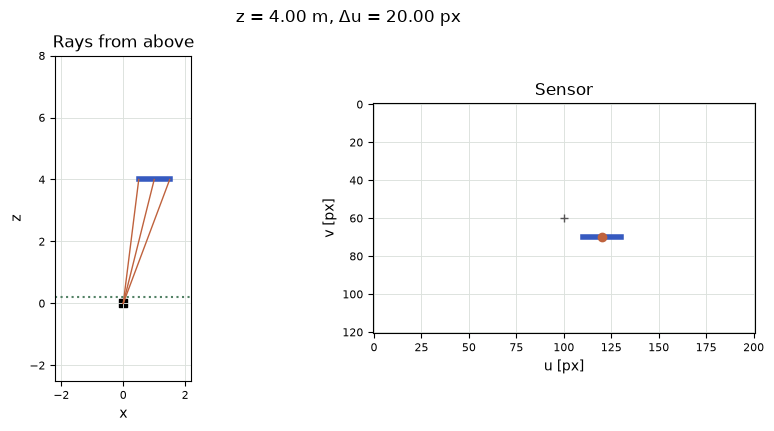

In [4]:
fig = demos.perspective_figure("en")
plt.show()

## 3. From a ratio to a pixel address

We have measured a direction. Now it needs a scale. A focal length $f_x=80$ pixels means that one unit of $x/z$ becomes 80 horizontal pixel intervals. In this experiment $f_y=80$ vertically as well. For example, $x/z=0.25$ gives $80\cdot0.25=20$ pixels to the right of the optical axis. The downward shift is $80\cdot0.125=10$ pixels.

For image width $W=201$, column centers are numbered 0 through 200, so the middle index is $c_x=(W-1)/2=100$. Height $H=121$ gives $c_y=60$. The pair is the principal point, where the optical axis meets the image. Real calibration estimates its location separately and can place it off center. Pixel centers sit at integer coordinates, but a geometric ray can hit between them. The calculation keeps fractional coordinates until an operation actually needs an integer address.

$$
\begin{aligned}
u&=c_x+f_x\,x/z=100+80\cdot1/4=120,\\
v&=c_y+f_y\,y/z=60+80\cdot0.5/4=70.
\end{aligned}
$$

Here $u$ increases rightward and $v$ downward. The left tip of the bar has $x=0.5$ and therefore $u=110$. The right tip has $x=1.5$ and $u=130$. Subtracting gives $130-110=20$ pixel intervals of length. Coloring every integer center including both endpoints would touch 21 centers. Geometric length and the number of touched centers measure different things.

In [5]:
principal = (100, 60)
for x in [.5, 1, 1.5]:
    print(f"x={x:g} m →", geo.project_point([x,.5,4], 80, principal, near=.2), "px")
np.testing.assert_allclose(geo.project_point(p, (80,100), principal), [120,72.5])

x=0.5 m → [110.  70.] px
x=1 m → [120.  70.] px
x=1.5 m → [130.  70.] px


## 4. The same steps in matrix form

The two focal lengths and the principal point fit into one matrix $K$. Its top row multiplies $f_x x$ and $c_x z$, then sums the products. The bottom row passes depth through untouched:

$$
K\begin{bmatrix}x\\y\\z\end{bmatrix}
=\begin{bmatrix}80&0&100\\0&80&60\\0&0&1\end{bmatrix}
\begin{bmatrix}1\\0.5\\4\end{bmatrix}
=\begin{bmatrix}80+400\\40+240\\4\end{bmatrix}
=\begin{bmatrix}480\\280\\4\end{bmatrix}.
$$

The first two entries still have units of pixels times meters. The last entry is depth in meters. Dividing by it gives the same address $(480/4,280/4)=(120,70)$ px. If the point starts in the world, $B^{\mathsf T}(P-C)$ from the previous lesson goes into $K$ first.

The camera moves 2 m forward. The world point stays put, but its depth is now $4-2=2$. The middle lands at $(140,80)$ px and the length of the bar is $80\cdot1/2=40$ px. A 160 px focal length from the old camera position produces the same result for **this** bar. For a second object at depth 8 m, moving 2 m forward enlarges it only by a factor of $8/6$. Doubling focal length enlarges both objects by two. This difference in relative size distinguishes camera motion from a change of focal length.

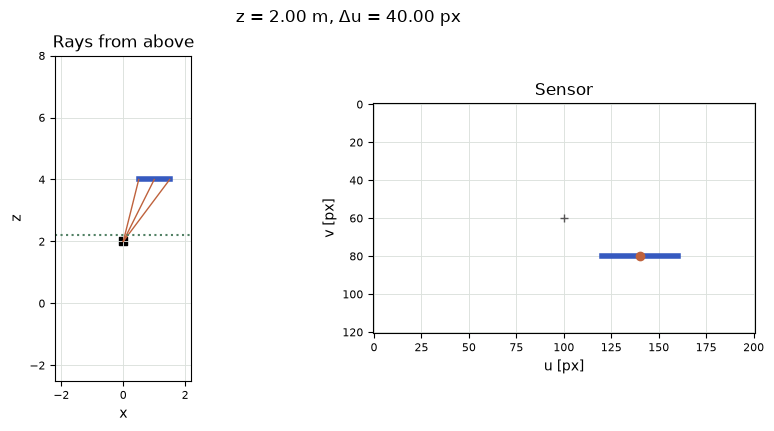

In [6]:
fig = demos.perspective_figure("en", camera_z=2)
plt.show()

In [7]:
K = np.array([[80, 0, 100], [0, 80, 60], [0, 0, 1]])
h = K @ p
print("Kp =", h, "   (u, v) =", h[:2]/h[2])
for z in [4, 8]:
    print(f"z={z}: move → {80/(z-2):.2f} px; zoom → {160/z:.2f} px")

Kp = [480. 280.   4.]    (u, v) = [120.  70.]
z=4: move → 40.00 px; zoom → 40.00 px
z=8: move → 13.33 px; zoom → 20.00 px


## 5. Two ways to lose a point

For $z=0.5$ m and $x=1$ m the ray still points forward, but $u=100+80/0.5=260$ is already beyond the right edge. At $z=0.2$ a different rule applies. This scene keeps depths **strictly greater** than 0.2 m. The near plane protects against huge values close to division by zero. A line segment with endpoints on opposite sides needs geometric clipping. Our bar is parallel to the sensor, so its endpoints pass or fail together.

**An experiment.** We know pixel $(120,70)$ and focal length 80 but have lost the depth. Which two different points could have produced it?

<details>
<summary>Working it out</summary>

Subtracting principal point $(100,60)$ from the address leaves $(20,10)$. Division by 80 gives the direction $(0.25,0.125,1)$. Multiplying by any positive depth gives a point on the ray. Depths 2 and 4 give $(0.5,0.25,2)$ and $(1,0.5,4)$ m.

</details>

**At the edge.** With $f_x=80$ and $z=4$, which world $x$ lands exactly in the middle of the last column?

<details>
<summary>Working it out</summary>

The camera is at the world origin and the axes agree. The last column has $u=200$. The offset from the center is $200-100=100$ px. The ratio $x/z=100/80=1.25$, so $x=4\cdot1.25=5$ m. The sensor edge itself lies another half pixel beyond this column's center.

</details>

The convention for $K$ and the world-to-camera transformation appears in [OpenCV's pinhole camera model](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html).